<a href="https://colab.research.google.com/github/naubergois/curso-clip-difusao-colab/blob/main/exercicios/aula2-exercicio5-ultima-da-busca.ipynb" target="_blank"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Aula 2, exercício 5: Última da busca

Qual foto ficou em último na mesma busca?

A pergunta usa o que a aula [2. Classificar sem treinar, e buscar a foto](https://colab.research.google.com/github/naubergois/curso-clip-difusao-colab/blob/main/notebooks/02-clip-zero-shot-e-busca.ipynb) deixa pronto. **Ambiente de execução → Executar tudo** carrega isso, deixa uma célula para tentar e, no fim, confere uma solução.

In [1]:
import sys
!{sys.executable} -m pip install -q transformers accelerate matplotlib pillow

## Preparação

A preparação baixa as três fotos, mede a dos gatos com a palavra solta e com a frase, e ordena a busca. Ficam prontos `classes`, `probs_palavra`, `probs_frase`, `fotos` e `notas_busca`.

In [2]:
import os
import warnings

os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("TRANSFORMERS_VERBOSITY", "error")
warnings.filterwarnings("ignore", message=".*unauthenticated requests.*")

import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from PIL import Image
from transformers import CLIPModel, CLIPProcessor


def baixar(url, destino):
    destino = Path(destino)
    if not destino.exists():
        urllib.request.urlretrieve(url, destino)
    return destino


def dispositivo():
    if torch.cuda.is_available():
        return "cuda"
    if torch.backends.mps.is_available():
        return "mps"
    return "cpu"


def como_vetor(saida):
    """A biblioteca devolve o tensor direto, ou embrulhado. A gente quer o tensor."""
    if torch.is_tensor(saida):
        return saida
    for nome in ("pooler_output", "image_embeds", "text_embeds"):
        valor = getattr(saida, nome, None)
        if torch.is_tensor(valor):
            return valor
    raise TypeError(type(saida))


def normalizar(v):
    return v / v.norm(dim=-1, keepdim=True)


device = dispositivo()
model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
model.eval()
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
print("dispositivo:", device)


def pontuar(imagem, textos):
    """Reparte 100% entre os textos recebidos. Não é uma probabilidade do mundo."""
    entradas = processor(text=textos, images=imagem, return_tensors="pt", padding=True).to(device)
    with torch.no_grad():
        logits = model(**entradas).logits_per_image[0]
    return logits.softmax(dim=0).detach().cpu()


def vetor_imagem(imagens):
    entradas = processor(images=imagens, return_tensors="pt").to(device)
    with torch.no_grad():
        saida = model.get_image_features(pixel_values=entradas["pixel_values"])
    return normalizar(como_vetor(saida))


def vetor_texto(textos):
    entradas = processor(text=textos, return_tensors="pt", padding=True).to(device)
    with torch.no_grad():
        saida = model.get_text_features(
            input_ids=entradas["input_ids"],
            attention_mask=entradas["attention_mask"],
        )
    return normalizar(como_vetor(saida))


def barras(rotulos, valores, titulo):
    plt.figure(figsize=(7, 2.6))
    plt.barh(list(rotulos)[::-1], [float(v) for v in valores][::-1])
    plt.xlim(0, 1)
    plt.title(titulo)
    plt.tight_layout()
    plt.show()

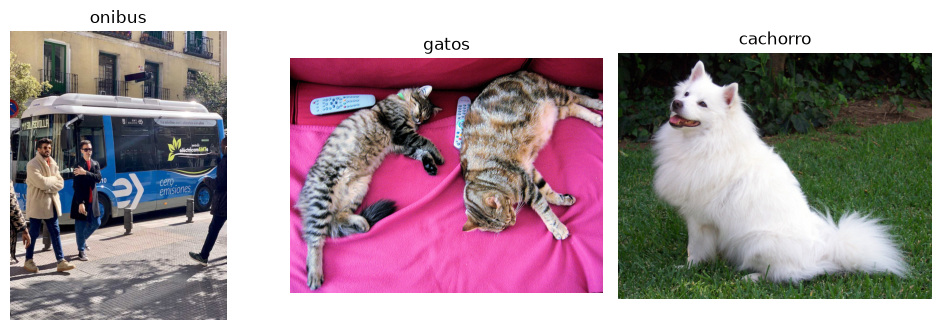

palavra solta
   96.6%  cat
    0.7%  dog
    2.8%  bus
frase
   99.4%  a photo of a cat
    0.5%  a photo of a dog
    0.1%  a photo of a bus
 0.297  onibus
 0.147  gatos
 0.134  cachorro


In [3]:
import matplotlib.pyplot as plt
from PIL import Image

arquivos = {
    "onibus": "https://www.ultralytics.com/images/bus.jpg",
    "gatos": "http://images.cocodataset.org/val2017/000000039769.jpg",
    "cachorro": "https://raw.githubusercontent.com/pytorch/hub/master/images/dog.jpg",
}
fotos = {
    nome: Image.open(baixar(url, f"{nome}.jpg")).convert("RGB")
    for nome, url in arquivos.items()
}

plt.figure(figsize=(10, 3.4))
for i, (nome, img) in enumerate(fotos.items()):
    plt.subplot(1, 3, i + 1)
    plt.imshow(img)
    plt.title(nome)
    plt.axis("off")
plt.tight_layout()
plt.show()

classes = ["cat", "dog", "bus"]
alvo = fotos["gatos"]
probs_palavra = pontuar(alvo, classes)
probs_frase = pontuar(alvo, [f"a photo of a {c}" for c in classes])
print("palavra solta")
for nome, p in zip(classes, probs_palavra):
    print(f"  {float(p):6.1%}  {nome}")
print("frase")
for nome, p in zip(classes, probs_frase):
    print(f"  {float(p):6.1%}  a photo of a {nome}")

consulta = "a photo of a bus on the street"
vetores = vetor_imagem(list(fotos.values()))
notas_busca = (vetores @ vetor_texto([consulta]).T).squeeze(1).detach().cpu()
for nome, nota in sorted(zip(fotos, notas_busca), key=lambda par: float(par[1]), reverse=True):
    print(f"{float(nota):6.3f}  {nome}")

In [4]:
# @title Correção automática (rode, não precisa ler)
_classes = list(classes)
_palavra = [float(p) for p in probs_palavra]
_frase = [float(p) for p in probs_frase]
_nomes = list(fotos.keys())
_busca = [float(n) for n in notas_busca]
_ordem = [nome for _, nome in sorted(zip(_busca, _nomes), reverse=True)]
_i_palavra = _palavra.index(max(_palavra))
_i_frase = _frase.index(max(_frase))

VERIFICAR = {
    1: lambda r: r == _classes[_i_palavra],
    2: lambda r: r == _classes[_i_frase],
    3: lambda r: bool(r) == (_i_palavra != _i_frase),
    4: lambda r: r == _ordem[0],
    5: lambda r: r == _ordem[-1],
    6: lambda r: abs(float(r) - (_busca[_nomes.index(_ordem[0])] - _busca[_nomes.index(_ordem[1])])) < 1e-3,
}

_acertos = {}


def conferir(n, resposta):
    if resposta is None:
        print(f"Exercício {n}: ainda sem resposta.")
        return
    try:
        certo = bool(VERIFICAR[n](resposta))
    except Exception as erro:
        certo = False
        print(f"  (a verificação deu erro: {erro})")
    _acertos[n] = certo
    print(f"Exercício {n}: " + ("✅ certo!" if certo else "❌ ainda não. Releia o enunciado e tente de novo."))


def placar():
    print(f"{sum(_acertos.values())} de {len(VERIFICAR)} exercícios certos.")

## Sua vez

Qual foto ficou em último na mesma busca?

*Dica:* argmin é o inverso de argmax.

Troque o `None` pela sua resposta e rode a célula.

In [5]:
resposta = None

conferir(5, resposta)

Exercício 5: ainda sem resposta.


## Uma solução

Compare com o que você fez. Existem outros caminhos certos: o que vale é a `conferir` aprovar.

In [6]:
resposta = list(fotos.keys())[int(notas_busca.argmin())]

conferir(5, resposta)

Exercício 5: ✅ certo!


## O que fica

Próximo: [Aula 2, exercício 6: Folga do primeiro](https://colab.research.google.com/github/naubergois/curso-clip-difusao-colab/blob/main/exercicios/aula2-exercicio6-folga-do-primeiro.ipynb).